# DM-2 — Exercice 2 : Cartes de saillance

## Objectif

L'objectif est de visualiser les pixels les plus importants pour la classification des chiffres manuscrits MNIST avec AdaBoost.

Nous analysons les *decision stumps* entraînés lors de l'exercice 1. Chaque stump sélectionne un pixel pour effectuer sa séparation.

Deux types de cartes sont construits :

- **Carte de fréquence :** nombre de fois où chaque pixel est sélectionné.
- **Carte pondérée :** somme des poids AdaBoost associés aux stumps utilisant chaque pixel.

Les cartes sont comparées pour 10, 50 et 100 estimateurs et pour les deux problèmes de classification binaire.

In [2]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from pathlib import Path

# Définition des répertoires
PROJECT_ROOT = Path.cwd().parent
RESULTS_DIR = PROJECT_ROOT / "results"
MODELS_DIR = RESULTS_DIR / "models"
SALIENCY_DIR = RESULTS_DIR / "saliency_maps"

SALIENCY_DIR.mkdir(parents=True, exist_ok=True)

print("Répertoire des modèles :", MODELS_DIR)
print("Répertoire des cartes :", SALIENCY_DIR)


Répertoire des modèles : /home/lucca/00_projetos/DM2_Machine_Learning/results/models
Répertoire des cartes : /home/lucca/00_projetos/DM2_Machine_Learning/results/saliency_maps


In [3]:

# Configurations étudiées
datasets_names = ["3_vs_8", "0_4_vs_5_9"]
n_estimators_values = [10, 50, 100]

# Chargement des modèles entraînés
modeles = {}

for dataset_name in datasets_names:
    for n_estimators in n_estimators_values:

        cle = f"{dataset_name}_stump_{n_estimators}"
        chemin = MODELS_DIR / f"{cle}.joblib"

        if chemin.exists():
            modeles[cle] = joblib.load(chemin)
            print(f"Modèle chargé : {cle}")
        else:
            print(f"Modèle introuvable : {chemin}")

print(f"\nNombre de modèles chargés : {len(modeles)}")


Modèle chargé : 3_vs_8_stump_10
Modèle chargé : 3_vs_8_stump_50
Modèle chargé : 3_vs_8_stump_100
Modèle chargé : 0_4_vs_5_9_stump_10
Modèle chargé : 0_4_vs_5_9_stump_50
Modèle chargé : 0_4_vs_5_9_stump_100

Nombre de modèles chargés : 6


## 2.1 Construction des cartes de saillance

Pour chaque stump, nous identifions le pixel utilisé dans la première division de l'arbre.

La fréquence de sélection d'un pixel correspond au nombre de stumps qui utilisent ce pixel.

La carte pondérée prend également en compte le poids de chaque stump dans la combinaison AdaBoost.

Les vecteurs de 784 valeurs sont ensuite reconstruits en matrices de 28 × 28 pixels.

In [4]:

def calculer_cartes_saillance(modele):
    """
    Calcule les cartes de fréquence et de saillance pondérée
    à partir des decision stumps d'un modèle AdaBoost.
    """

    frequence = np.zeros(784, dtype=float)
    importance = np.zeros(784, dtype=float)

    poids = modele.estimator_weights_

    for i, stump in enumerate(modele.estimators_):

        # Indice du pixel utilisé à la racine
        pixel = stump.tree_.feature[0]

        # Une valeur négative signifie qu'il n'y a pas de division
        if pixel < 0:
            continue

        # Fréquence de sélection
        frequence[pixel] += 1

        # Importance pondérée
        importance[pixel] += abs(poids[i])

    return (
        frequence.reshape(28, 28),
        importance.reshape(28, 28)
    )


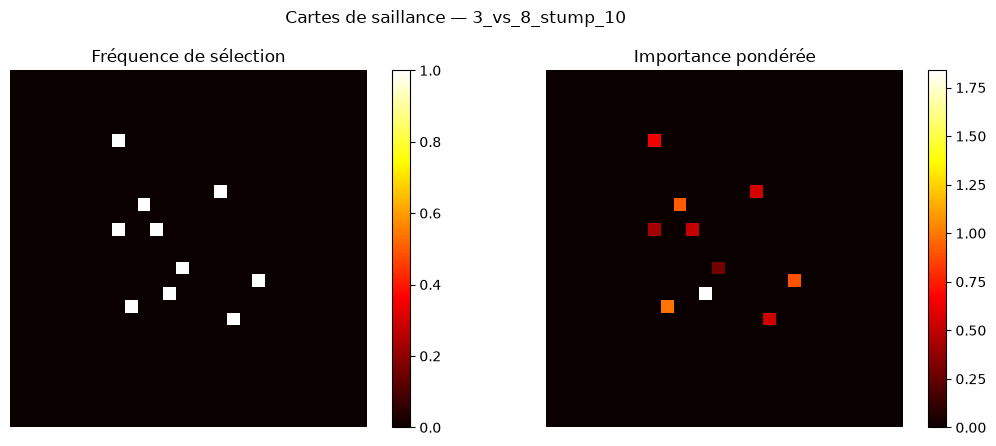

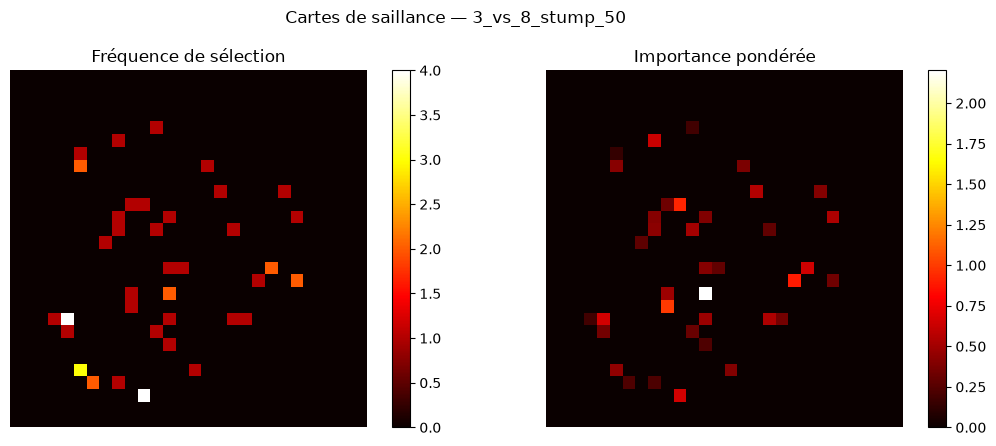

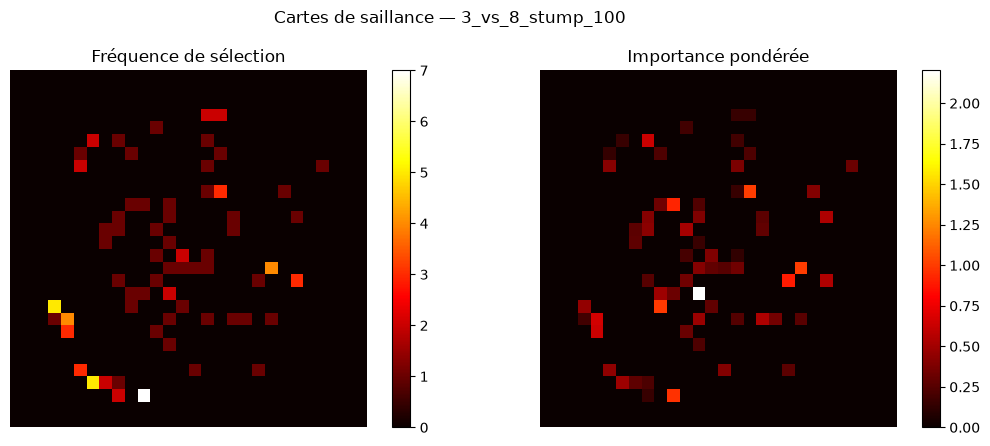

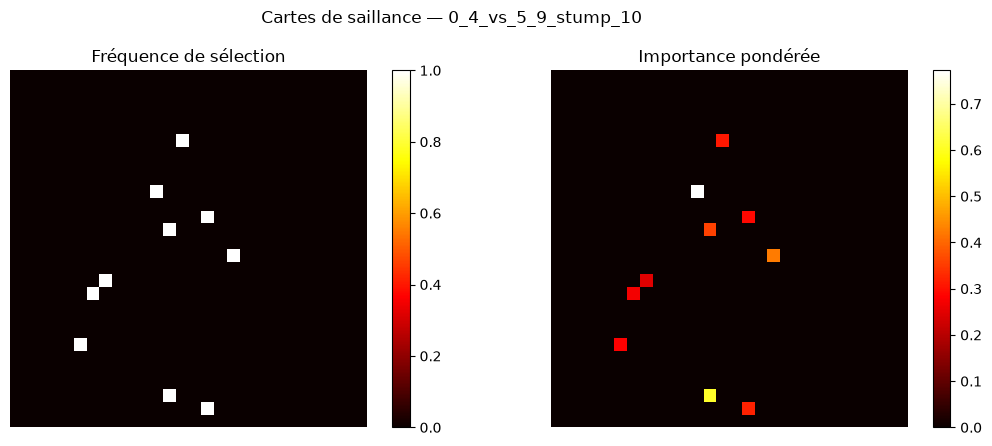

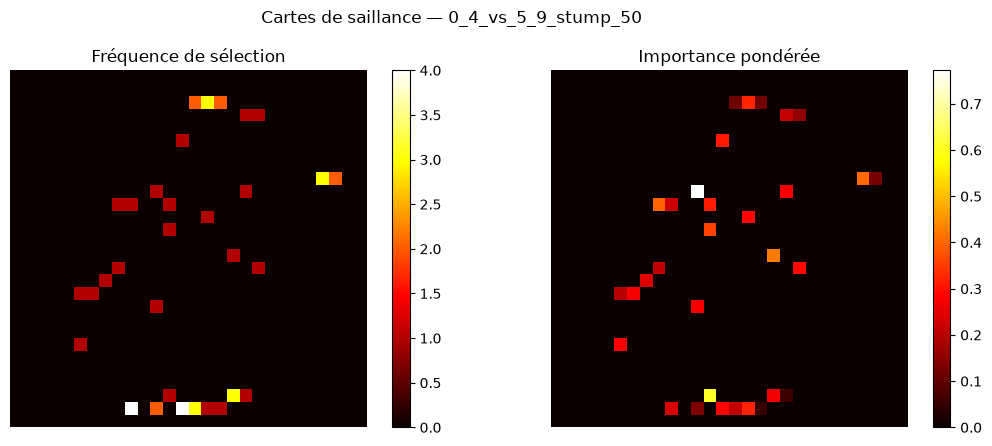

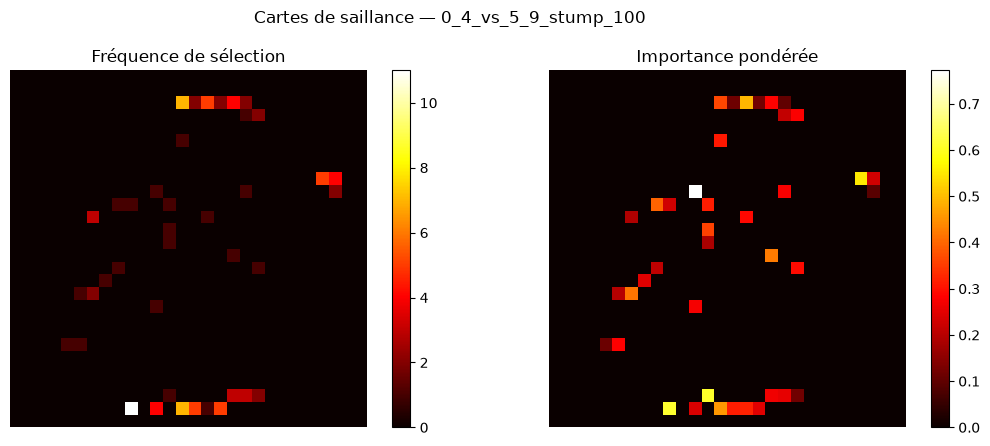

In [5]:

cartes = {}

for cle, modele in modeles.items():

    carte_frequence, carte_ponderee = calculer_cartes_saillance(modele)

    cartes[cle] = {
        "frequence": carte_frequence,
        "ponderee": carte_ponderee
    }

    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

    im1 = axes[0].imshow(
        carte_frequence,
        cmap="hot",
        interpolation="nearest"
    )
    axes[0].set_title("Fréquence de sélection")
    axes[0].axis("off")
    plt.colorbar(im1, ax=axes[0], fraction=0.046)

    im2 = axes[1].imshow(
        carte_ponderee,
        cmap="hot",
        interpolation="nearest"
    )
    axes[1].set_title("Importance pondérée")
    axes[1].axis("off")
    plt.colorbar(im2, ax=axes[1], fraction=0.046)

    fig.suptitle(f"Cartes de saillance — {cle}")
    plt.tight_layout()

    plt.savefig(
        SALIENCY_DIR / f"saillance_{cle}.png",
        dpi=150,
        bbox_inches="tight"
    )

    plt.show()


## 2.2 Comparaison des cartes de saillance

Nous comparons les cartes de saillance obtenues avec 10, 50 et 100 estimateurs.

L'objectif est d'observer comment le nombre d'étapes de boosting influence la répartition spatiale des pixels sélectionnés.

Une attention particulière est portée à la discrimination entre les chiffres 3 et 8, dont les différences visuelles facilitent l'interprétation.

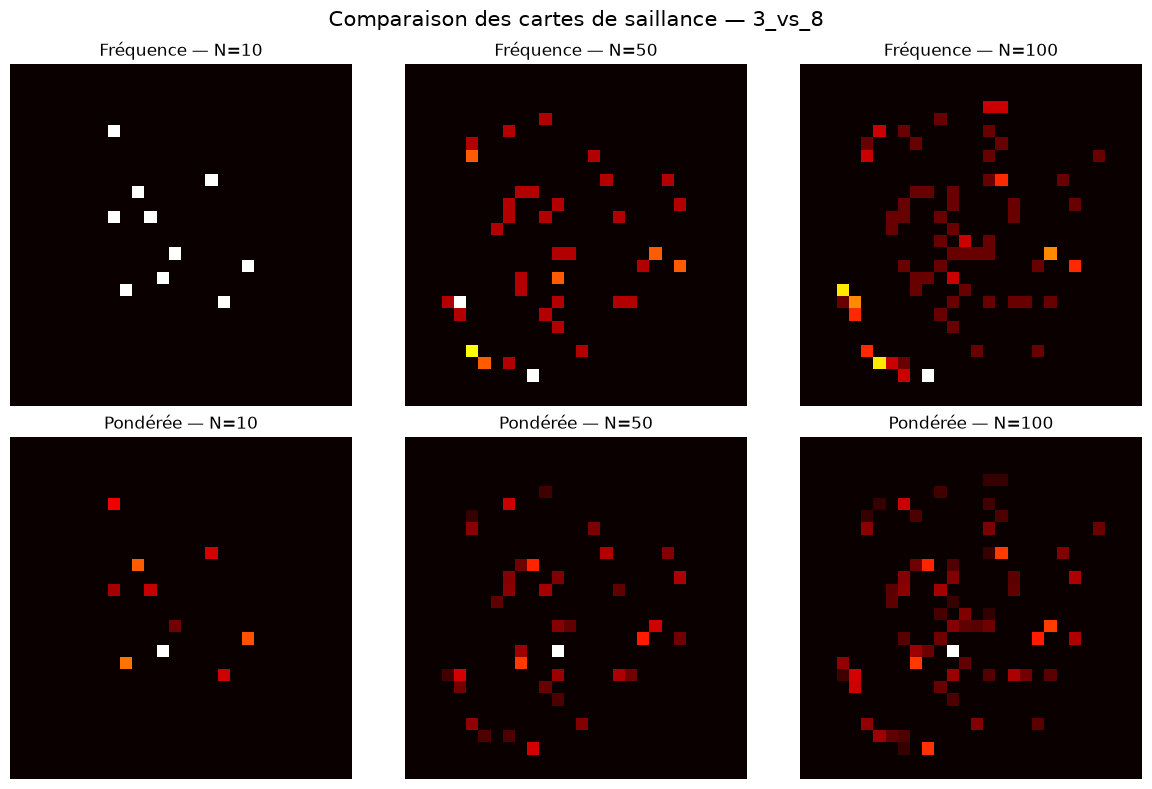

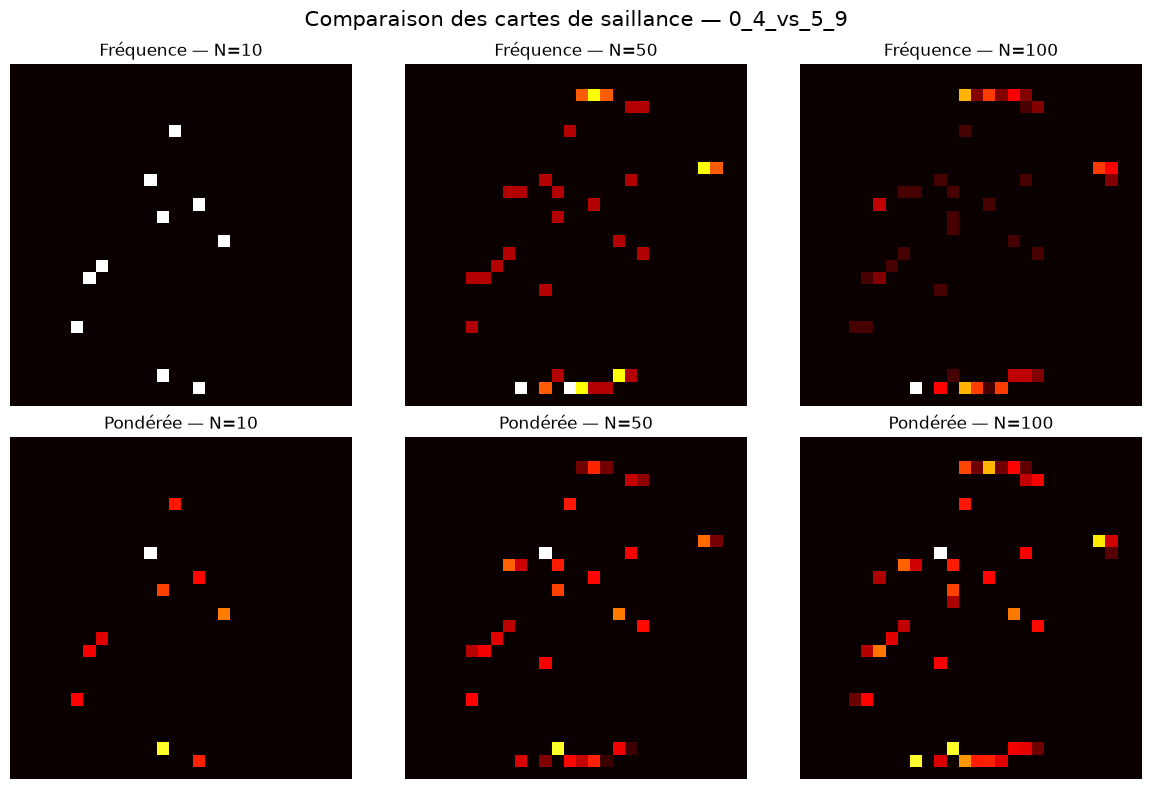

In [6]:

for dataset_name in datasets_names:

    fig, axes = plt.subplots(2, 3, figsize=(12, 8))

    for j, n_estimators in enumerate(n_estimators_values):

        cle = f"{dataset_name}_stump_{n_estimators}"

        if cle not in cartes:
            axes[0, j].axis("off")
            axes[1, j].axis("off")
            continue

        freq = cartes[cle]["frequence"]
        pond = cartes[cle]["ponderee"]

        axes[0, j].imshow(freq, cmap="hot")
        axes[0, j].set_title(f"Fréquence — N={n_estimators}")

        axes[1, j].imshow(pond, cmap="hot")
        axes[1, j].set_title(f"Pondérée — N={n_estimators}")

        for i in range(2):
            axes[i, j].axis("off")

    fig.suptitle(
        f"Comparaison des cartes de saillance — {dataset_name}",
        fontsize=15
    )

    plt.tight_layout()

    plt.savefig(
        SALIENCY_DIR / f"comparaison_{dataset_name}.png",
        dpi=150,
        bbox_inches="tight"
    )

    plt.show()
